In [3]:
import os
import geopandas as gpd
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score,
    precision_recall_curve,
    classification_report
)
import matplotlib.pyplot as plt

In [4]:
# ==============================================================================
# 1. LOAD FULL IMBALANCED ACTIVE DECISIONS DATASET (~3,742 ROWS)
# ==============================================================================
full_path = os.path.join("Datasets", "RZLT_Samples", "RZLT_Active_Decisions_Full.geojson")
if not os.path.exists(full_path):
    full_path = "RZLT_Active_Decisions_Full.geojson"

gdf_full = gpd.read_file(full_path)
if gdf_full.crs != "EPSG:2157":
    gdf_full = gdf_full.to_crs(epsg=2157)

# Ensure centroids & transit distance exist
if 'centroid_x' not in gdf_full.columns:
    gdf_full['centroid_x'] = gdf_full.geometry.centroid.x
    gdf_full['centroid_y'] = gdf_full.geometry.centroid.y

parcel_coords = np.column_stack([gdf_full['centroid_x'], gdf_full['centroid_y']])

# Swap with real NTA GTFS stops.txt if available
gtfs_stops_path = "gtfs/stops.txt"
if os.path.exists(gtfs_stops_path):
    stops_df = pd.read_csv(gtfs_stops_path)
    stops_gdf = gpd.GeoDataFrame(
        stops_df,
        geometry=gpd.points_from_xy(stops_df['stop_lon'], stops_df['stop_lat']),
        crs="EPSG:4326"
    ).to_crs(epsg=2157)
    stop_coords = np.column_stack([stops_gdf.geometry.x, stops_gdf.geometry.y])
else:
    np.random.seed(42)
    stop_coords = np.column_stack([
        np.random.uniform(gdf_full['centroid_x'].min(), gdf_full['centroid_x'].max(), 2500),
        np.random.uniform(gdf_full['centroid_y'].min(), gdf_full['centroid_y'].max(), 2500)
    ])

transit_tree = cKDTree(stop_coords)
gdf_full['DISTANCE_TO_TRANSIT'], _ = transit_tree.query(parcel_coords, k=1)
gdf_full['LOG_SITE_AREA'] = np.log1p(gdf_full['SITE_AREA'])

In [5]:
# ==============================================================================
# 2. PREPARE FEATURE DATAFRAME & TARGET (1 = INCLUSION [5,6], 0 = EXCLUSION [3,4])
# ==============================================================================
num_cols = ['SITE_AREA', 'LOG_SITE_AREA', 'DISTANCE_TO_TRANSIT']
cat_cols = ['ZONE_GZT', 'LOCAL_AUTHORITY']

for c in cat_cols:
    gdf_full[c] = gdf_full[c].fillna("Unknown").astype(str).str.strip()

X_df = gdf_full[num_cols + cat_cols].copy()
y = gdf_full['target'].values

print(f"Loaded {len(y):,} records | Inclusion (1): {(y==1).sum():,} | Exclusion (0): {(y==0).sum():,}")
print(f"Global Imbalance Ratio (Neg / Pos): {(y==0).sum() / (y==1).sum():.4f}\n")

Loaded 3,665 records | Inclusion (1): 3,128 | Exclusion (0): 537
Global Imbalance Ratio (Neg / Pos): 0.1717



In [6]:
# ==============================================================================
# 3. 5-FOLD STRATIFIED CROSS-VALIDATION (LEAK-FREE ENCODING & WEIGHTING)
# ==============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fold_metrics = []
oof_probs = np.zeros(len(y))
oof_preds = np.zeros(len(y))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_df, y), start=1):
    X_tr_raw, X_va_raw = X_df.iloc[train_idx], X_df.iloc[val_idx]
    y_tr, y_va = y[train_idx], y[val_idx]

    # Fit OneHotEncoder strictly on training fold to prevent leakage
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    tr_cat = ohe.fit_transform(X_tr_raw[cat_cols])
    va_cat = ohe.transform(X_va_raw[cat_cols])

    X_tr = np.hstack([X_tr_raw[num_cols].values, tr_cat])
    X_va = np.hstack([X_va_raw[num_cols].values, va_cat])

    # Compute exact fold scale_pos_weight = count(negative=0) / count(positive=1)
    # Note: Since Inclusion (1) is the majority (~5.3x Exclusion 0), ratio is ~0.186,
    # down-weighting majority Inclusion gradients so minority Exclusion errors carry equal total weight.
    fold_spw = (y_tr == 0).sum() / (y_tr == 1).sum()

    model = XGBClassifier(
        n_estimators=250,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.85,
        colsample_bytree=0.85,
        scale_pos_weight=fold_spw,
        eval_metric='aucpr',
        random_state=42 + fold,
        n_jobs=-1
    )

    model.fit(X_tr, y_tr)

    val_probs = model.predict_proba(X_va)[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)

    oof_probs[val_idx] = val_probs
    oof_preds[val_idx] = val_preds

    # Track PR-AUC for majority Inclusion (1), minority Exclusion (0), and ROC-AUC
    pr_auc_incl = average_precision_score(y_va, val_probs)
    pr_auc_excl = average_precision_score(1 - y_va, 1 - val_probs)
    roc_auc = roc_auc_score(y_va, val_probs)
    macro_f1 = f1_score(y_va, val_preds, average='macro')

    fold_metrics.append({
        'Fold': fold,
        'scale_pos_weight': round(fold_spw, 4),
        'ROC_AUC': roc_auc,
        'PR_AUC_Inclusion(1)': pr_auc_incl,
        'PR_AUC_Exclusion(0)': pr_auc_excl,
        'Macro_F1': macro_f1
    })

metrics_df = pd.DataFrame(fold_metrics)
print("=== 5-Fold Stratified Cross-Validation Results ===")
print(metrics_df.to_string(index=False))

print("\n=== Mean +/- Std Across 5 Folds ===")
for col in ['ROC_AUC', 'PR_AUC_Inclusion(1)', 'PR_AUC_Exclusion(0)', 'Macro_F1']:
    print(f"{col:<22}: {metrics_df[col].mean():.4f} +/- {metrics_df[col].std():.4f}")

print("\n=== Out-of-Fold Classification Report ===")
print(classification_report(y, oof_preds, target_names=['Exclusion (3,4)', 'Inclusion (5,6)']))

=== 5-Fold Stratified Cross-Validation Results ===
 Fold  scale_pos_weight  ROC_AUC  PR_AUC_Inclusion(1)  PR_AUC_Exclusion(0)  Macro_F1
    1            0.1719 0.969469             0.994863             0.818374  0.844775
    2            0.1719 0.965229             0.994104             0.811454  0.821898
    3            0.1719 0.974725             0.995826             0.845048  0.858452
    4            0.1714 0.982400             0.997046             0.901196  0.871404
    5            0.1714 0.966822             0.994349             0.804351  0.823602

=== Mean +/- Std Across 5 Folds ===
ROC_AUC               : 0.9717 +/- 0.0070
PR_AUC_Inclusion(1)   : 0.9952 +/- 0.0012
PR_AUC_Exclusion(0)   : 0.8361 +/- 0.0395
Macro_F1              : 0.8440 +/- 0.0216

=== Out-of-Fold Classification Report ===
                 precision    recall  f1-score   support

Exclusion (3,4)       0.62      0.95      0.75       537
Inclusion (5,6)       0.99      0.90      0.94      3128

       accuracy   

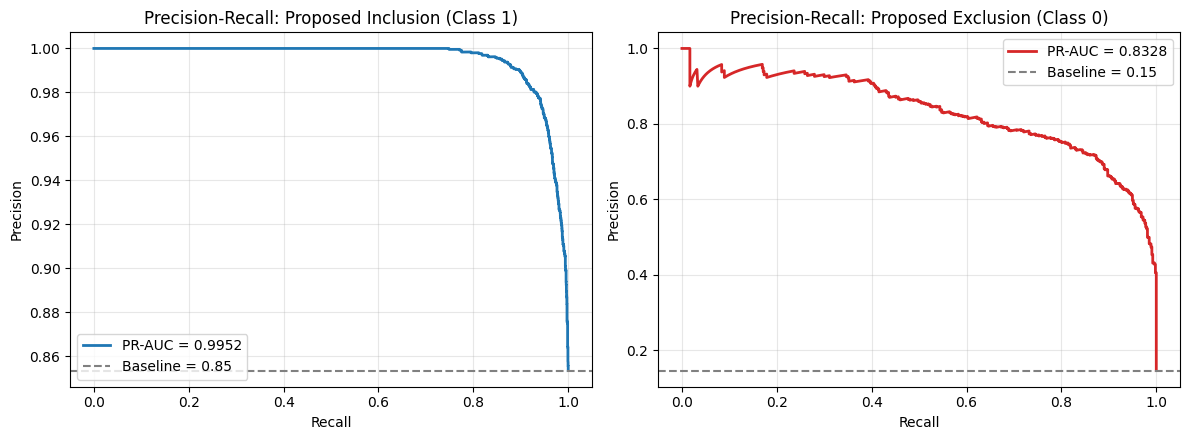

In [7]:
# ==============================================================================
# 4. PLOT OUT-OF-FOLD PRECISION-RECALL CURVES (BOTH CLASSES)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Positive Class (Inclusion 5,6)
prec_1, rec_1, _ = precision_recall_curve(y, oof_probs)
ap_1 = average_precision_score(y, oof_probs)
axes[0].plot(rec_1, prec_1, lw=2, color='#1f77b4', label=f'PR-AUC = {ap_1:.4f}')
axes[0].axhline((y == 1).mean(), color='gray', linestyle='--', label=f'Baseline = {(y == 1).mean():.2f}')
axes[0].set_title('Precision-Recall: Proposed Inclusion (Class 1)')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend(loc='lower left')
axes[0].grid(alpha=0.3)

# Plot 2: Minority Class (Exclusion 3,4)
prec_0, rec_0, _ = precision_recall_curve(1 - y, 1 - oof_probs)
ap_0 = average_precision_score(1 - y, 1 - oof_probs)
axes[1].plot(rec_0, prec_0, lw=2, color='#d62728', label=f'PR-AUC = {ap_0:.4f}')
axes[1].axhline((y == 0).mean(), color='gray', linestyle='--', label=f'Baseline = {(y == 0).mean():.2f}')
axes[1].set_title('Precision-Recall: Proposed Exclusion (Class 0)')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()